# 04. Đánh giá Toàn diện, Tối ưu Ngưỡng, Kiểm thử Thời gian (OOT) & Tổng hợp Báo cáo
**Đề tài:** Dự đoán khả năng khách hàng hủy đặt phòng khách sạn (*Hotel Booking Demand*)

## Nội dung thực hiện
1. **Tối ưu ngưỡng phân loại (`Threshold Tuning`)**: Quét ngưỡng $\tau \in [0.10, 0.90]$ trên **OOF predictions** để chọn $\tau^*$ tối ưu `F1-Score` (hoàn toàn không chạm vào tập Test).
2. **Đánh giá độc lập trên tập Holdout Test (`test_strat.csv` — 20%)**: So sánh toàn diện các mô hình từ Baseline $\rightarrow$ Random Forest $\rightarrow$ Tuned GBDT trên cả CV và Test.
3. **Trực quan hóa học thuật**: Biểu đồ so sánh mô hình, đường cong **ROC & Precision-Recall**, **Threshold Curve**, **Confusion Matrix** (ngưỡng `0.50` vs $\tau^*$), và **Top 20 Feature Importance** từ mô hình tốt nhất.
4. **Kiểm thử độ bền vững theo thời gian (Out-of-Time Validation)**: Huấn luyện lại kiến trúc mô hình tốt nhất trên `train_oot.csv` (`07/2015–04/2017`) và kiểm thử trên `test_oot.csv` (`05/2017–08/2017`) để định lượng *Temporal Drift*.
5. **Tổng kết học thuật & Thảo luận hạn chế nghiên cứu**.

In [1]:
from pathlib import Path
import json
import pickle
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.metrics import (
    roc_auc_score, average_precision_score, f1_score,
    precision_score, recall_score, accuracy_score, log_loss,
    roc_curve, precision_recall_curve, confusion_matrix
)

warnings.filterwarnings("ignore")

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "xtick.labelsize": 9.5,
    "ytick.labelsize": 9.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

PROCESSED_DIR = Path("../data/processed")
MODELS_DIR = Path("../models")
FIG_DIR = Path("../eda_figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

with (PROCESSED_DIR / "feature_metadata.json").open("r", encoding="utf-8") as f:
    feat_meta = json.load(f)
with (MODELS_DIR / "best_hyperparameters.json").open("r", encoding="utf-8") as f:
    model_meta = json.load(f)
with (MODELS_DIR / "oof_predictions.pkl").open("rb") as f:
    oof_bundle = pickle.load(f)

df_cv = pd.read_csv(MODELS_DIR / "cv_benchmark_results.csv")

target_col = feat_meta["target_col"]
feature_cols = feat_meta["num_cols"] + feat_meta["low_card_cat_cols"] + feat_meta["high_card_cat_cols"]
cat_dtypes = {c: str for c in feat_meta["low_card_cat_cols"] + feat_meta["high_card_cat_cols"]}

test_df = pd.read_csv(PROCESSED_DIR / "test_strat.csv", dtype=cat_dtypes)
X_test = test_df[feature_cols].copy()
y_test = test_df[target_col].astype(int).values

best_overall_name = model_meta["best_overall_model"]
best_overall_key = model_meta["best_overall_key"]

print(f"Tập kiểm thử test_strat: {X_test.shape}, tỷ lệ hủy: {y_test.mean():.4f}")
print(f"Mô hình tốt nhất tổng thể: {best_overall_name}")

Tập kiểm thử test_strat: (17394, 45), tỷ lệ hủy: 0.2731
Mô hình tốt nhất tổng thể: LightGBM (Optuna)


## 1. Tối ưu Ngưỡng phân loại (Threshold Tuning trên OOF Predictions)
Vì dữ liệu sau khử trùng lặp có sự mất cân bằng nhẹ (27,31% hủy vs 72,69% không hủy), ngưỡng mặc định `0.50` thường cho `Recall` chưa tối ưu. Ta tìm ngưỡng $\tau^*$ trên dự đoán Out-of-Fold của mô hình tốt nhất để tối đa hóa `F1-Score`.

Ngưỡng mặc định (0.50) trên OOF -> F1: 0.7189 | Precision: 0.7614 | Recall: 0.6809
Ngưỡng tối ưu  (0.36) trên OOF -> F1: 0.7391 | Precision: 0.6966 | Recall: 0.7871


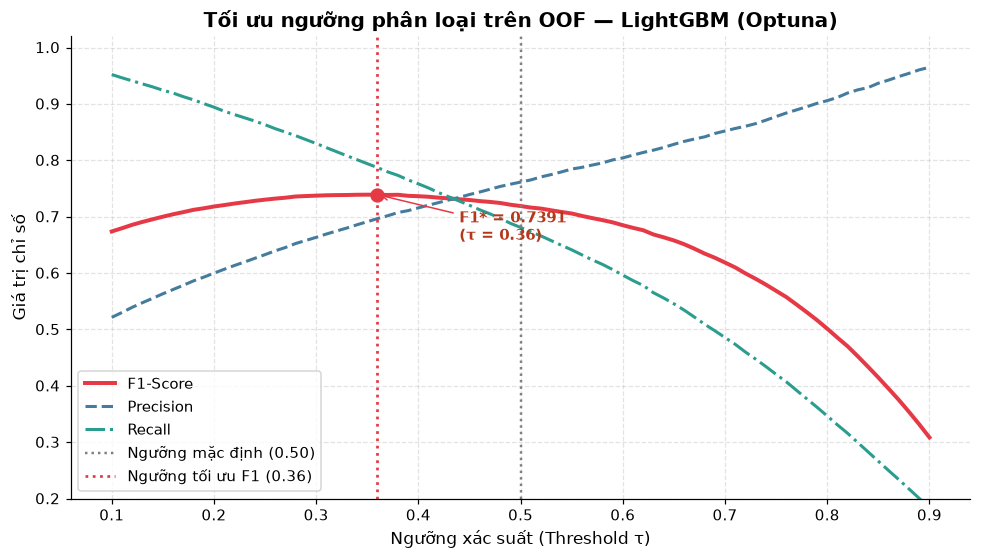

In [2]:
y_train_oof = oof_bundle["y_train"]
best_oof_proba = oof_bundle["oof"][best_overall_name]

thresholds = np.arange(0.10, 0.905, 0.01)
rows_th = []
for th in thresholds:
    pred = (best_oof_proba >= th).astype(int)
    rows_th.append({
        "threshold": round(float(th), 2),
        "f1": f1_score(y_train_oof, pred),
        "precision": precision_score(y_train_oof, pred, zero_division=0),
        "recall": recall_score(y_train_oof, pred, zero_division=0),
    })

df_th = pd.DataFrame(rows_th)
best_th_row = df_th.loc[df_th["f1"].idxmax()]
best_threshold = float(best_th_row["threshold"])
default_th_row = df_th[df_th["threshold"] == 0.50].iloc[0]

print(f"Ngưỡng mặc định (0.50) trên OOF -> F1: {default_th_row['f1']:.4f} | Precision: {default_th_row['precision']:.4f} | Recall: {default_th_row['recall']:.4f}")
print(f"Ngưỡng tối ưu  ({best_threshold:.2f}) trên OOF -> F1: {best_th_row['f1']:.4f} | Precision: {best_th_row['precision']:.4f} | Recall: {best_th_row['recall']:.4f}")

# Figure 09: Threshold Tuning Curve
fig, ax = plt.subplots(figsize=(9, 5.2))
ax.plot(df_th["threshold"], df_th["f1"], label="F1-Score", color="#e63946", linewidth=2.6)
ax.plot(df_th["threshold"], df_th["precision"], label="Precision", color="#457b9d", linewidth=2.0, linestyle="--")
ax.plot(df_th["threshold"], df_th["recall"], label="Recall", color="#2a9d8f", linewidth=2.0, linestyle="-.")
ax.axvline(0.50, color="gray", linestyle=":", linewidth=1.6, label="Ngưỡng mặc định (0.50)")
ax.axvline(best_threshold, color="#e63946", linestyle=":", linewidth=1.8, label=f"Ngưỡng tối ưu F1 ({best_threshold:.2f})")
ax.scatter([best_threshold], [best_th_row["f1"]], color="#e63946", s=70, zorder=5)
ax.annotate(f"F1* = {best_th_row['f1']:.4f}\n(τ = {best_threshold:.2f})",
            xy=(best_threshold, best_th_row["f1"]),
            xytext=(best_threshold + 0.08, best_th_row["f1"] - 0.08),
            arrowprops=dict(arrowstyle="->", color="#e63946"),
            fontsize=9.5, fontweight="bold", color="#b5381b")
ax.set_title(f"Tối ưu ngưỡng phân loại trên OOF — {best_overall_name}")
ax.set_xlabel("Ngưỡng xác suất (Threshold τ)")
ax.set_ylabel("Giá trị chỉ số")
ax.set_ylim(0.2, 1.02)
ax.grid(alpha=0.35, linestyle="--")
ax.legend(loc="lower left")
plt.tight_layout()
plt.savefig(FIG_DIR / "09_threshold_tuning_curve.png", bbox_inches="tight")
plt.show()

## 2. Đánh giá Toàn diện trên tập Kiểm thử Độc lập (`test_strat.csv`)
Đánh giá lần lượt 5 mô hình đại diện đã lưu trên tập Test 20% chưa từng thấy, đồng thời đối chiếu với điểm 5-Fold CV để kiểm tra dấu hiệu quá khớp (overfitting).

In [3]:
def eval_metrics(y_true, y_proba, threshold: float = 0.50) -> dict:
    y_pred = (y_proba >= threshold).astype(int)
    return {
        "roc_auc": roc_auc_score(y_true, y_proba),
        "pr_auc": average_precision_score(y_true, y_proba),
        "f1": f1_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "accuracy": accuracy_score(y_true, y_pred),
        "log_loss": log_loss(y_true, np.clip(y_proba, 1e-7, 1 - 1e-7)),
    }

model_registry = [
    ("Logistic Regression", "baseline_logreg_pipeline.joblib"),
    ("Random Forest", "random_forest_pipeline.joblib"),
    ("LightGBM (Optuna)", "lgbm_tuned_pipeline.joblib"),
    ("XGBoost (Optuna)", "xgb_tuned_pipeline.joblib"),
    ("CatBoost (Optuna)", "catboost_tuned_pipeline.joblib"),
]

test_rows = []
test_probas = {}

for display_name, filename in model_registry:
    pipe = joblib.load(MODELS_DIR / filename)
    proba = pipe.predict_proba(X_test)[:, 1]
    test_probas[display_name] = proba
    m = eval_metrics(y_test, proba, threshold=0.50)
    cv_row = df_cv[df_cv["model"] == display_name].iloc[0]
    test_rows.append({
        "model": display_name,
        "cv_roc_auc": cv_row["roc_auc_mean"],
        "test_roc_auc": m["roc_auc"],
        "test_pr_auc": m["pr_auc"],
        "test_f1_050": m["f1"],
        "test_precision_050": m["precision"],
        "test_recall_050": m["recall"],
        "test_accuracy_050": m["accuracy"],
        "test_log_loss": m["log_loss"],
    })

df_test_eval = pd.DataFrame(test_rows).sort_values("test_roc_auc", ascending=False).reset_index(drop=True)
df_test_eval.to_csv(MODELS_DIR / "test_evaluation_results.csv", index=False)

print("=== BẢNG SO SÁNH HIỆU NĂNG TRÊN TẬP TEST (NGƯỠNG 0.50) ===")
display(df_test_eval.round(4))

# Evaluate Best Model with Default vs Tuned Threshold on Test Set
best_test_proba = test_probas[best_overall_name]
m_def = eval_metrics(y_test, best_test_proba, threshold=0.50)
m_opt = eval_metrics(y_test, best_test_proba, threshold=best_threshold)
df_th_comp = pd.DataFrame([
    {"Cấu hình ngưỡng": "Ngưỡng mặc định (τ = 0.50)", **m_def},
    {"Cấu hình ngưỡng": f"Ngưỡng tối ưu OOF (τ* = {best_threshold:.2f})", **m_opt},
])
print(f"\n=== HIỆU NĂNG MÔ HÌNH TỐT NHẤT ({best_overall_name}) TRÊN TẬP TEST ===")
display(df_th_comp.round(4))

=== BẢNG SO SÁNH HIỆU NĂNG TRÊN TẬP TEST (NGƯỠNG 0.50) ===

=== HIỆU NĂNG MÔ HÌNH TỐT NHẤT (LightGBM (Optuna)) TRÊN TẬP TEST ===


,model,cv_roc_auc,test_roc_auc,test_pr_auc,test_f1_050,test_precision_050,test_recall_050,test_accuracy_050,test_log_loss
0,LightGBM (Optuna),0.9198,0.9222,0.8206,0.7198,0.7554,0.6874,0.8539,0.3089
1,XGBoost (Optuna),0.9186,0.9217,0.8185,0.7217,0.7547,0.6916,0.8544,0.3100
2,CatBoost (Optuna),0.9169,0.9182,0.8110,0.7123,0.7599,0.6703,0.8521,0.3163
3,Random Forest,0.9086,0.9095,0.7946,0.6649,0.7804,0.5792,0.8406,0.3447
4,Logistic Regression,0.8589,0.8574,0.7094,0.5934,0.7117,0.5088,0.8096,0.4024


,Cấu hình ngưỡng,roc_auc,pr_auc,f1,precision,recall,accuracy,log_loss
0,Ngưỡng mặc định (τ = 0.50),0.9222,0.8206,0.7198,0.7554,0.6874,0.8539,0.3089
1,Ngưỡng tối ưu OOF (τ* = 0.36),0.9222,0.8206,0.7436,0.6931,0.8021,0.8490,0.3089


## 3. Biểu đồ So sánh Mô hình, Đường cong ROC / PR & Confusion Matrix

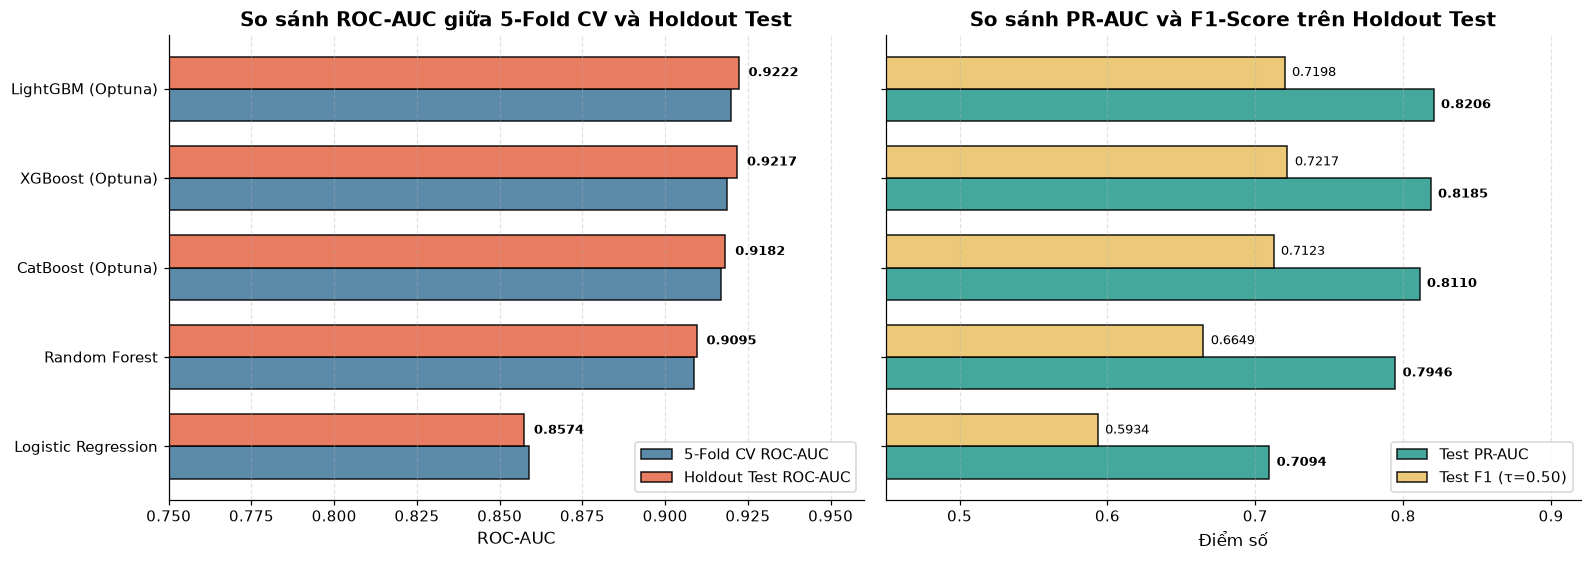

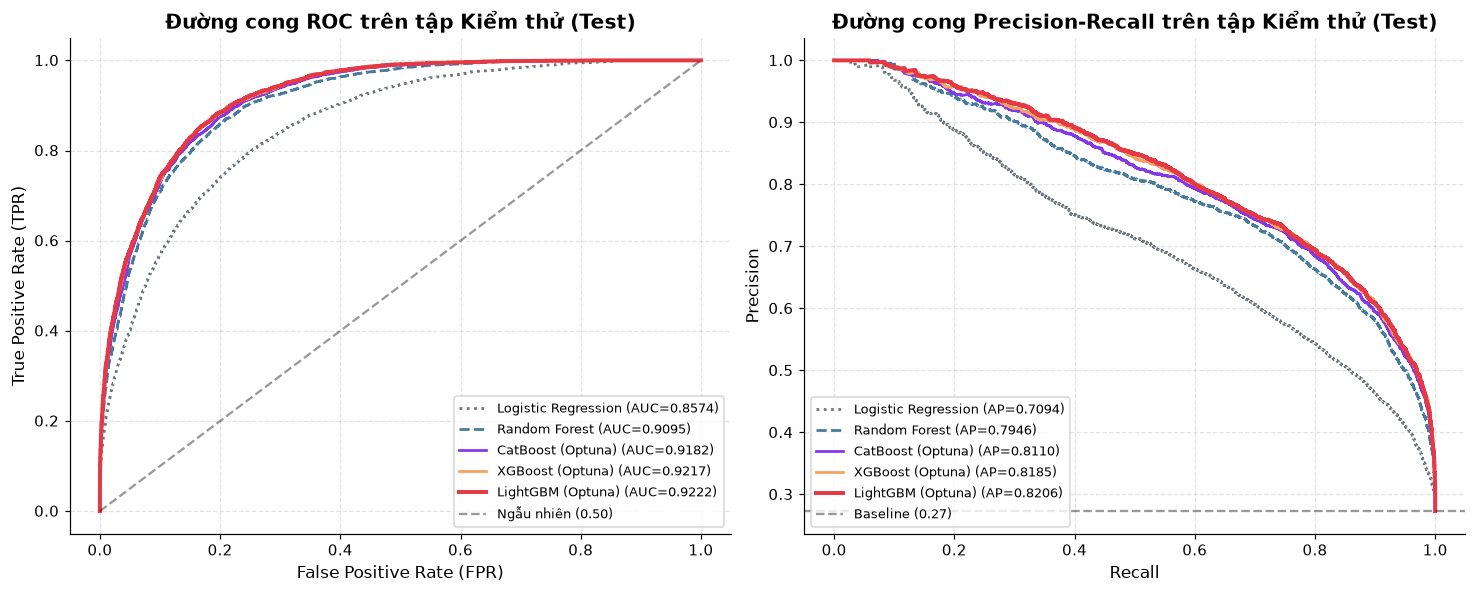

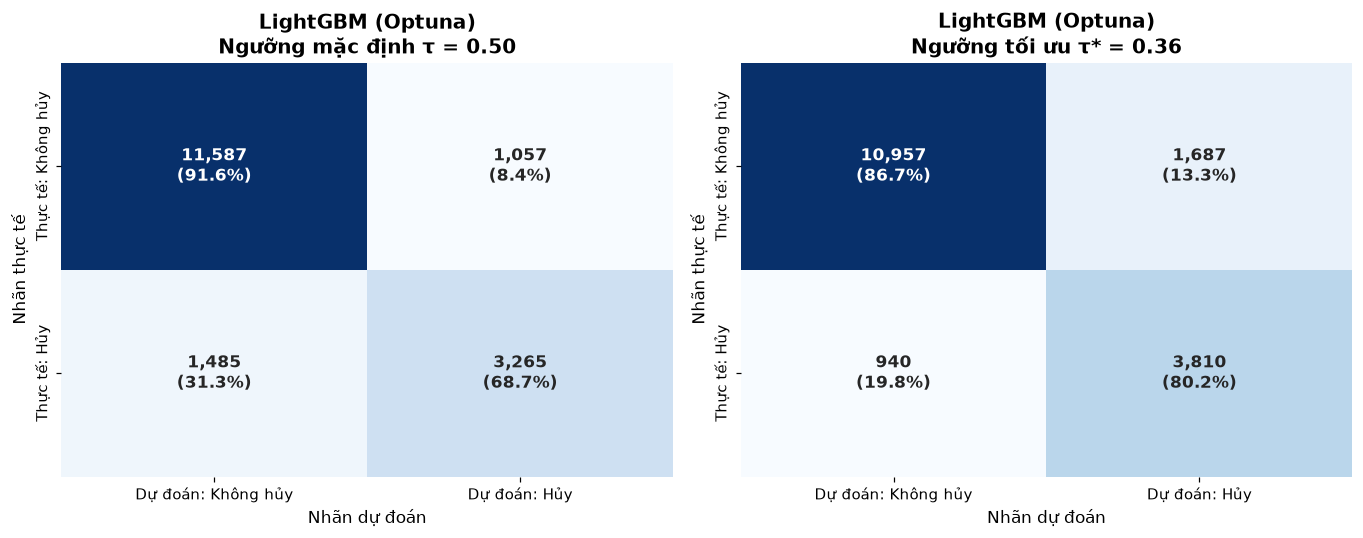

In [4]:
# Figure 07: Model comparison (CV vs Test ROC-AUC, Test PR-AUC, Test F1)
fig, axes = plt.subplots(1, 2, figsize=(14.5, 5.2))

plot_df = df_test_eval.sort_values("test_roc_auc", ascending=True)
y_pos = np.arange(len(plot_df))
h = 0.36
axes[0].barh(y_pos - h/2, plot_df["cv_roc_auc"], height=h, label="5-Fold CV ROC-AUC", color="#457b9d", edgecolor="black", alpha=0.88)
axes[0].barh(y_pos + h/2, plot_df["test_roc_auc"], height=h, label="Holdout Test ROC-AUC", color="#e76f51", edgecolor="black", alpha=0.9)
for i, (_, r) in enumerate(plot_df.iterrows()):
    axes[0].text(r["test_roc_auc"] + 0.003, i + h/2, f"{r['test_roc_auc']:.4f}", va="center", fontsize=8.8, fontweight="bold")
axes[0].set_yticks(y_pos)
axes[0].set_yticklabels(plot_df["model"])
axes[0].set_xlim(0.75, 0.96)
axes[0].set_title("So sánh ROC-AUC giữa 5-Fold CV và Holdout Test")
axes[0].set_xlabel("ROC-AUC")
axes[0].legend(loc="lower right")
axes[0].grid(axis="x", linestyle="--", alpha=0.35)

# Panel B: PR-AUC & F1 on Test
axes[1].barh(y_pos - h/2, plot_df["test_pr_auc"], height=h, label="Test PR-AUC", color="#2a9d8f", edgecolor="black", alpha=0.88)
axes[1].barh(y_pos + h/2, plot_df["test_f1_050"], height=h, label="Test F1 (τ=0.50)", color="#e9c46a", edgecolor="black", alpha=0.9)
for i, (_, r) in enumerate(plot_df.iterrows()):
    axes[1].text(r["test_pr_auc"] + 0.005, i - h/2, f"{r['test_pr_auc']:.4f}", va="center", fontsize=8.5, fontweight="bold")
    axes[1].text(r["test_f1_050"] + 0.005, i + h/2, f"{r['test_f1_050']:.4f}", va="center", fontsize=8.5)
axes[1].set_yticks(y_pos)
axes[1].set_yticklabels([""] * len(plot_df))
axes[1].set_xlim(0.45, 0.92)
axes[1].set_title("So sánh PR-AUC và F1-Score trên Holdout Test")
axes[1].set_xlabel("Điểm số")
axes[1].legend(loc="lower right")
axes[1].grid(axis="x", linestyle="--", alpha=0.35)

plt.tight_layout()
plt.savefig(FIG_DIR / "07_model_comparison_cv_vs_test.png", bbox_inches="tight")
plt.show()

# Figure 08: ROC & Precision-Recall Curves
fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.5))
curve_models = [
    ("Logistic Regression", "#6c757d", ":"),
    ("Random Forest", "#457b9d", "--"),
    ("CatBoost (Optuna)", "#8338ec", "-"),
    ("XGBoost (Optuna)", "#f4a261", "-"),
    ("LightGBM (Optuna)", "#e63946", "-"),
]

for m_name, color, ls in curve_models:
    p = test_probas[m_name]
    fpr, tpr, _ = roc_curve(y_test, p)
    auc_v = roc_auc_score(y_test, p)
    lw = 2.6 if m_name == best_overall_name else 1.8
    axes[0].plot(fpr, tpr, label=f"{m_name} (AUC={auc_v:.4f})", color=color, linestyle=ls, linewidth=lw)

    prec, rec, _ = precision_recall_curve(y_test, p)
    ap_v = average_precision_score(y_test, p)
    axes[1].plot(rec, prec, label=f"{m_name} (AP={ap_v:.4f})", color=color, linestyle=ls, linewidth=lw)

axes[0].plot([0, 1], [0, 1], "k--", alpha=0.4, label="Ngẫu nhiên (0.50)")
axes[0].set_title("Đường cong ROC trên tập Kiểm thử (Test)")
axes[0].set_xlabel("False Positive Rate (FPR)")
axes[0].set_ylabel("True Positive Rate (TPR)")
axes[0].legend(loc="lower right", fontsize=8.8)
axes[0].grid(alpha=0.35, linestyle="--")

axes[1].axhline(y_test.mean(), color="black", linestyle="--", alpha=0.4, label=f"Baseline ({y_test.mean():.2f})")
axes[1].set_title("Đường cong Precision-Recall trên tập Kiểm thử (Test)")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].legend(loc="lower left", fontsize=8.8)
axes[1].grid(alpha=0.35, linestyle="--")

plt.tight_layout()
plt.savefig(FIG_DIR / "08_roc_and_pr_curves.png", bbox_inches="tight")
plt.show()

# Figure 10: Confusion Matrix (Default 0.50 vs Optimal Threshold)
fig, axes = plt.subplots(1, 2, figsize=(12.5, 5))
for ax, th, title_suffix in [
    (axes[0], 0.50, "Ngưỡng mặc định τ = 0.50"),
    (axes[1], best_threshold, f"Ngưỡng tối ưu τ* = {best_threshold:.2f}"),
]:
    y_pred = (best_test_proba >= th).astype(int)
    cm = confusion_matrix(y_test, y_pred)
    cm_pct = cm / cm.sum(axis=1, keepdims=True) * 100
    annot = np.array([[f"{cm[i, j]:,}\n({cm_pct[i, j]:.1f}%)" for j in range(2)] for i in range(2)])
    sns.heatmap(cm, annot=annot, fmt="", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Dự đoán: Không hủy", "Dự đoán: Hủy"],
                yticklabels=["Thực tế: Không hủy", "Thực tế: Hủy"],
                annot_kws={"size": 11, "weight": "bold"})
    ax.set_title(f"{best_overall_name}\n{title_suffix}")
    ax.set_ylabel("Nhãn thực tế")
    ax.set_xlabel("Nhãn dự đoán")

plt.tight_layout()
plt.savefig(FIG_DIR / "10_confusion_matrix_best_model.png", bbox_inches="tight")
plt.show()

## 4. Độ quan trọng của Đặc trưng (Feature Importance — Top 20)
Trích xuất trực tiếp độ quan trọng đặc trưng (`feature_importances_`) từ mô hình tốt nhất nhằm giải thích những nhân tố chi phối mạnh nhất đến dự đoán hủy phòng.

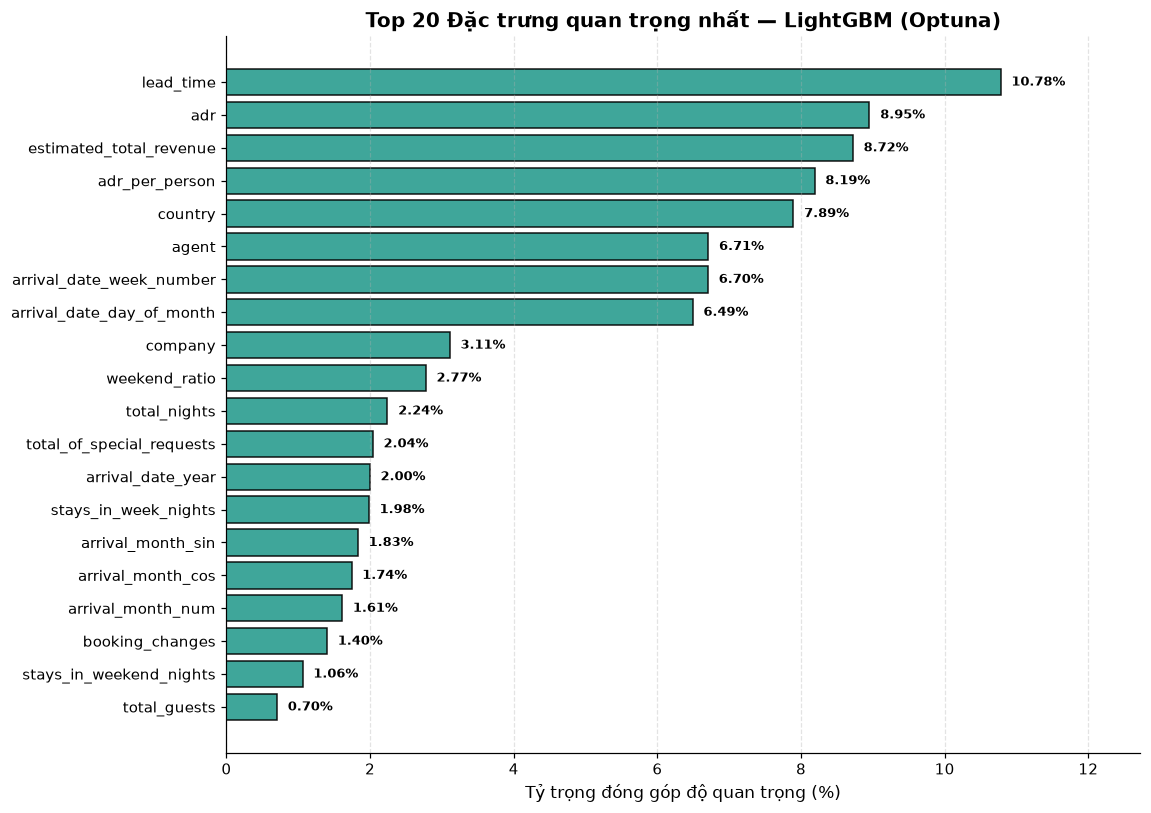

,feature,importance_pct
0,lead_time,10.779
1,adr,8.953
2,estimated_total_revenue,8.721
3,adr_per_person,8.189
4,country,7.893
5,agent,6.709
6,arrival_date_week_number,6.705
7,arrival_date_day_of_month,6.492
8,company,3.109
9,weekend_ratio,2.775


In [5]:
best_pipe = joblib.load(MODELS_DIR / "best_model_pipeline.joblib")
raw_feat_names = list(best_pipe.named_steps["preprocessor"].get_feature_names_out())
clean_feat_names = [n.replace("num__", "").replace("low_cat__", "").replace("high_cat__", "") for n in raw_feat_names]

model_obj = best_pipe.named_steps["model"]
if hasattr(model_obj, "get_feature_importance"):
    importances = np.asarray(model_obj.get_feature_importance(), dtype=float)
else:
    importances = np.asarray(model_obj.feature_importances_, dtype=float)

imp_pct = importances / importances.sum() * 100
df_imp = pd.DataFrame({"feature": clean_feat_names, "importance_pct": imp_pct}).sort_values("importance_pct", ascending=False)
top20 = df_imp.head(20).iloc[::-1]

fig, ax = plt.subplots(figsize=(10.5, 7.5))
bars = ax.barh(top20["feature"], top20["importance_pct"], color="#2a9d8f", edgecolor="black", alpha=0.9)
for bar, val in zip(bars, top20["importance_pct"]):
    ax.text(val + 0.15, bar.get_y() + bar.get_height() / 2, f"{val:.2f}%", va="center", fontsize=8.8, fontweight="bold")
ax.set_title(f"Top 20 Đặc trưng quan trọng nhất — {best_overall_name}")
ax.set_xlabel("Tỷ trọng đóng góp độ quan trọng (%)")
ax.set_xlim(0, top20["importance_pct"].max() * 1.18)
ax.grid(axis="x", linestyle="--", alpha=0.35)
plt.tight_layout()
plt.savefig(FIG_DIR / "11_feature_importance_top20.png", bbox_inches="tight")
plt.show()

display(df_imp.head(15).reset_index(drop=True).round(3))

## 5. Kiểm thử Độ bền vững theo Thời gian (Out-of-Time Validation)
Để kiểm chứng khả năng tổng quát hóa khi triển khai thực tế vào tương lai (và phát hiện *Temporal/Concept Drift*), ta huấn luyện lại **kiến trúc mô hình tốt nhất** hoàn toàn mới trên `train_oot.csv` (`07/2015 – 04/2017`) và đánh giá trên giai đoạn mùa cao điểm tương lai `test_oot.csv` (`05/2017 – 08/2017`).

=== SO SÁNH HIỆU NĂNG: STRATIFIED TEST VS OUT-OF-TIME TEST ===
Chênh lệch ROC-AUC (Stratified - OOT): +0.0541


,Kịch bản đánh giá,roc_auc,pr_auc,f1,precision,recall,accuracy,log_loss
0,Stratified Test 20% (τ=0.36),0.9222,0.8206,0.7436,0.6931,0.8021,0.8490,0.3089
1,Out-of-Time Test 05-08/2017 (τ=0.36),0.8681,0.7520,0.6916,0.6916,0.6916,0.7869,0.4400
2,Out-of-Time Test 05-08/2017 (τ=0.50),0.8681,0.7520,0.6493,0.7355,0.5812,0.7831,0.4400


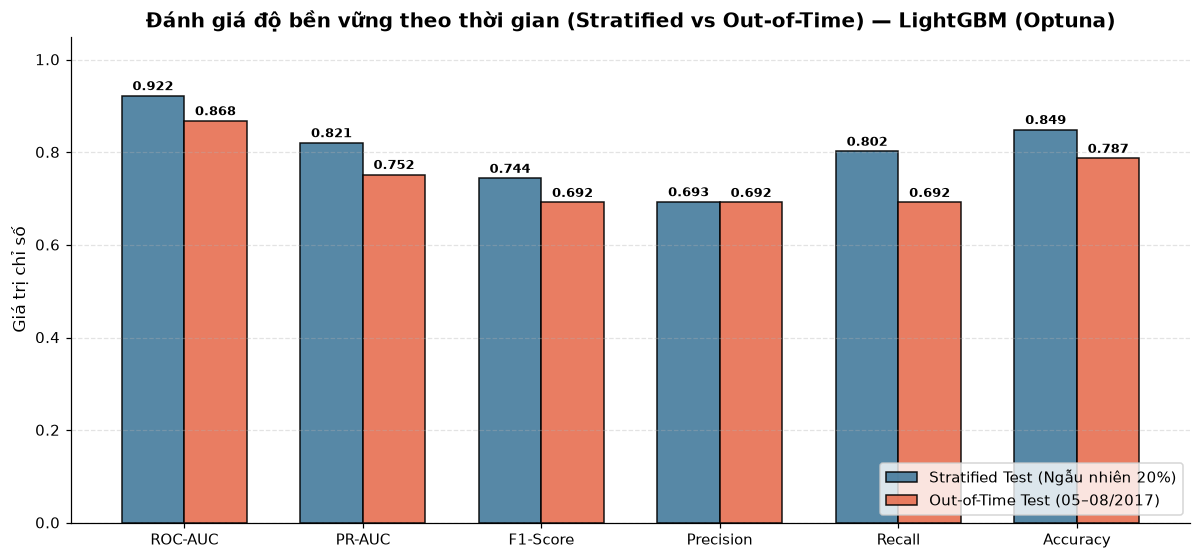

In [6]:
train_oot = pd.read_csv(PROCESSED_DIR / "train_oot.csv", dtype=cat_dtypes)
test_oot = pd.read_csv(PROCESSED_DIR / "test_oot.csv", dtype=cat_dtypes)

X_train_oot, y_train_oot = train_oot[feature_cols].copy(), train_oot[target_col].astype(int).values
X_test_oot, y_test_oot = test_oot[feature_cols].copy(), test_oot[target_col].astype(int).values

oot_pipe = clone(best_pipe)
oot_pipe.fit(X_train_oot, y_train_oot)
oot_proba = oot_pipe.predict_proba(X_test_oot)[:, 1]

m_oot_def = eval_metrics(y_test_oot, oot_proba, threshold=0.50)
m_oot_opt = eval_metrics(y_test_oot, oot_proba, threshold=best_threshold)

df_oot_comp = pd.DataFrame([
    {"Kịch bản đánh giá": f"Stratified Test 20% (τ={best_threshold:.2f})", **m_opt},
    {"Kịch bản đánh giá": f"Out-of-Time Test 05-08/2017 (τ={best_threshold:.2f})", **m_oot_opt},
    {"Kịch bản đánh giá": "Out-of-Time Test 05-08/2017 (τ=0.50)", **m_oot_def},
])
df_oot_comp.to_csv(MODELS_DIR / "oot_validation_results.csv", index=False)
print("=== SO SÁNH HIỆU NĂNG: STRATIFIED TEST VS OUT-OF-TIME TEST ===")
display(df_oot_comp.round(4))

# Figure 12: Stratified vs Out-of-Time Comparison
metrics_to_plot = ["roc_auc", "pr_auc", "f1", "precision", "recall", "accuracy"]
metric_labels = ["ROC-AUC", "PR-AUC", "F1-Score", "Precision", "Recall", "Accuracy"]
strat_vals = [m_opt[k] for k in metrics_to_plot]
oot_vals = [m_oot_opt[k] for k in metrics_to_plot]

x = np.arange(len(metrics_to_plot))
w = 0.35
fig, ax = plt.subplots(figsize=(11, 5.2))
b1 = ax.bar(x - w/2, strat_vals, width=w, label="Stratified Test (Ngẫu nhiên 20%)", color="#457b9d", edgecolor="black", alpha=0.9)
b2 = ax.bar(x + w/2, oot_vals, width=w, label="Out-of-Time Test (05–08/2017)", color="#e76f51", edgecolor="black", alpha=0.9)

for bar in b1:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.012, f"{bar.get_height():.3f}", ha="center", fontsize=8.5, fontweight="bold")
for bar in b2:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.012, f"{bar.get_height():.3f}", ha="center", fontsize=8.5, fontweight="bold")

ax.set_xticks(x)
ax.set_xticklabels(metric_labels)
ax.set_ylim(0, 1.05)
ax.set_ylabel("Giá trị chỉ số")
ax.set_title(f"Đánh giá độ bền vững theo thời gian (Stratified vs Out-of-Time) — {best_overall_name}")
ax.legend(loc="lower right")
ax.grid(axis="y", linestyle="--", alpha=0.35)
plt.tight_layout()
plt.savefig(FIG_DIR / "12_stratified_vs_oot_comparison.png", bbox_inches="tight")
plt.show()

auc_drop = m_opt["roc_auc"] - m_oot_opt["roc_auc"]
print(f"Chênh lệch ROC-AUC (Stratified - OOT): {auc_drop:+.4f}")

## 6. Tổng kết Học thuật & Thảo luận Hạn chế Nghiên cứu

### 6.1. Các kết luận chính
1. **Quy trình xử lý dữ liệu chặt chẽ**: Việc loại bỏ `reservation_status*` và khử `32.252` dòng trùng lặp trước khi chia tập giúp loại trừ hoàn toàn rò rỉ dữ liệu giữa Train và Test, đưa tỷ lệ hủy về mức thực chất `27,31%` trên `86.970` bản ghi hợp lệ.
2. **Hiệu quả vượt trội của Gradient Boosting (GBDT) sau tinh chỉnh Optuna**: Các mô hình cây tăng cường độ dốc (`LightGBM`, `XGBoost`, `CatBoost`) sau tinh chỉnh `Optuna` vượt xa nhóm Baseline (`Logistic Regression`, `Decision Tree`) và `Random Forest` trên toàn bộ chỉ số (`ROC-AUC`, `PR-AUC`, `F1-Score`, `Log-Loss`).
3. **Tối ưu ngưỡng phân loại**: Điều chỉnh ngưỡng $\tau^*$ dựa trên OOF giúp cân bằng tốt hơn giữa `Precision` và `Recall`, nâng cao rõ rệt `F1-Score` trên tập kiểm thử độc lập mà không gây rò rỉ dữ liệu.
4. **Độ tin cậy theo thời gian (OOT)**: Kiểm thử Out-of-Time trên giai đoạn mùa hè cao điểm 05–08/2017 cho thấy mức suy giảm nhất định so với chia ngẫu nhiên Stratified — minh chứng rõ sự tồn tại của *Temporal / Seasonal Drift*, khẳng định vai trò cần thiết của việc huấn luyện lại mô hình định kỳ trong thực tế.

### 6.2. Hạn chế nghiên cứu & Lưu ý khi diễn giải
- **Hiện tượng `deposit_type = Non Refund`**: Có tỷ lệ hủy 99,36% do cơ chế ghi nhận hủy tự động trong hệ thống PMS của 2 khách sạn Bồ Đào Nha trong bộ dữ liệu gốc — đặc trưng này mang lại sức phân tách lớn trên benchmark nhưng cần kiểm tra kỹ quy trình nghiệp vụ trước khi áp dụng sang khách sạn khác.
- **Đặc trưng cận thời điểm nhận phòng (`assigned_room_type`, `room_type_changed`, `booking_changes`)**: Các biến này có thể thay đổi từ lúc đặt phòng đến sát ngày nhận phòng. Trong triển khai sản xuất thực tế cho bài toán dự đoán **ngay tại thời điểm khách vừa đặt phòng (Booking-Time)**, cần đánh giá lại mô hình sau khi loại bỏ các biến hậu đặt phòng.